# 1 import necessary data

In [1]:
import tensorflow as tf
import keras
from matplotlib import pyplot as plt
import numpy as np
from keras import Sequential
from keras.layers import Conv2D,MaxPool2D,UpSampling2D

# 2 import data

In [2]:
(X_train, _), (X_test, _)=keras.datasets.mnist.load_data(path="mnist.npz")

In [3]:
X_train.shape,X_test.shape

((60000, 28, 28), (10000, 28, 28))

# 3 data preparation

### 3.1 add the channnel

In [7]:
X_train=X_train.reshape(60000, 28, 28,1)
X_test=X_test.reshape(10000, 28, 28,1)

In [8]:
X_train.shape,X_test.shape

((60000, 28, 28, 1), (10000, 28, 28, 1))

### 3.2 normalize

In [9]:
X_train=X_train/255.0
X_test=X_test/255.0

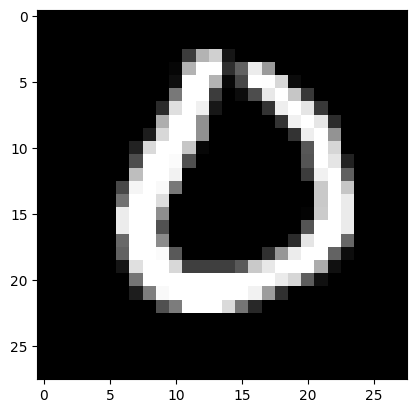

In [22]:
plt.imshow(X_train[2500],cmap="grey")

### 3.3 add noise

In [23]:
import numpy as np

In [29]:
X_train_noise=X_train+ 0.2*np.random.normal(loc=0.0, scale=1.0, size=X_train.shape)
X_test_noise=X_test+ 0.2*np.random.normal(loc=0.0, scale=1.0, size=X_test.shape)

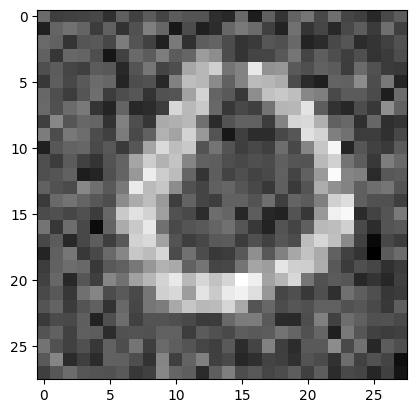

In [30]:
plt.imshow(X_train_noise[2500],cmap="grey")

In [31]:
X_train_noise.max(),X_test_noise.min()

(np.float64(2.0558129271939865), np.float64(-1.0904689095489661))

# 3.4 add clip

In [37]:
X_train_clipped=np.clip(a=X_train_noise,a_min=0.,a_max=1.)# i will have positive values
X_test_clipped=np.clip(a=X_test_noise,a_min=0.,a_max=1.)

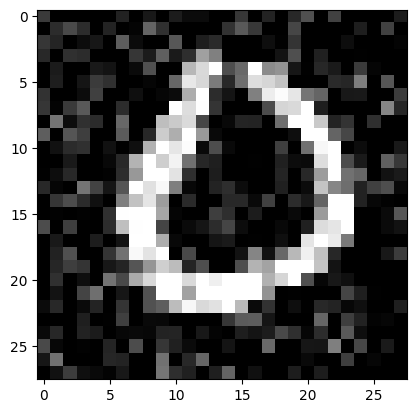

In [38]:
plt.imshow(X_train_clipped[2500],cmap="grey")

# 4 model building

In [39]:
from keras import Sequential
from keras.layers import Conv2D,MaxPool2D,UpSampling2D

In [52]:
model=Sequential()

# encoder- compress the info

model.add(Conv2D(filters=32,kernel_size=(3,3),strides=(1, 1),padding='same',activation='relu',input_shape=(28,28,1)))
model.add(MaxPool2D(pool_size=(2, 2),))
model.add(Conv2D(filters=8,kernel_size=(3,3),strides=(1, 1),padding='same',activation='relu',))
model.add(MaxPool2D(pool_size=(2, 2),))

# decoder -Expands

model.add(Conv2D(filters=8,kernel_size=(3,3),strides=(1, 1),padding='same',activation='relu',))
model.add(UpSampling2D(size=(2, 2),))
model.add(Conv2D(filters=32,kernel_size=(3,3),strides=(1, 1),padding='same',activation='relu'))
model.add(UpSampling2D(size=(2, 2),))
model.add(Conv2D(filters=1,kernel_size=(3,3),strides=(1, 1),padding='same',activation='relu'))

model.summary()

Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_14 (Conv2D)                   │ (None, 28, 28, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_9 (MaxPooling2D)       │ (None, 14, 14, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_15 (Conv2D)                   │ (None, 14, 14, 8)           │           2,312 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_10 (MaxPooling2D)      │ (None, 7, 7, 8)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_16 (Conv2D)                   │ (None, 7, 7, 8)             │             584 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ up_sampling2d_4 (UpSampling2D)       │ (None, 14, 14, 8)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_17 (Conv2D)                   │ (None, 14, 14, 32)          │           2,336 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ up_sampling2d_5 (UpSampling2D)       │ (None, 28, 28, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_18 (Conv2D)                   │ (None, 28, 28, 1)           │             289 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 5,841 (22.82 KB)

 Trainable params: 5,841 (22.82 KB)

 Non-trainable params: 0 (0.00 B)

# 5 model compliation

In [53]:
model.compile(optimizer='adam',loss="mean_squared_error",metrics=["accuracy"],)

# 6 model training

In [54]:
model.fit(x=X_train_clipped,y=X_train,batch_size=32,epochs=5,validation_data=(X_test,X_test_clipped),)

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 18s 9ms/step - accuracy: 0.8136 - loss: 0.0113 - val_accuracy: 0.4601 - val_loss: 0.0267
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 16s 9ms/step - accuracy: 0.8147 - loss: 0.0068 - val_accuracy: 0.4605 - val_loss: 0.0256
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 16s 9ms/step - accuracy: 0.8149 - loss: 0.0061 - val_accuracy: 0.4607 - val_loss: 0.0253
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 16s 9ms/step - accuracy: 0.8149 - loss: 0.0057 - val_accuracy: 0.4607 - val_loss: 0.0252
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 16s 9ms/step - accuracy: 0.8150 - loss: 0.0055 - val_accuracy: 0.4610 - val_loss: 0.0247


# 7 model evaluate

In [55]:
model.evaluate(X_test,X_test_clipped)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.4610 - loss: 0.0247


[0.02474905364215374, 0.46095821261405945]

# 8 model predict

In [57]:
y_pred=model.predict(X_test_clipped)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step


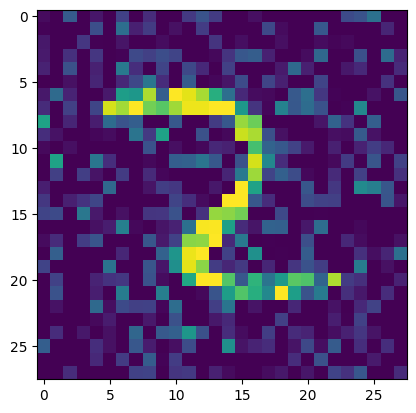

In [63]:
plt.imshow(X_test_clipped[2500])

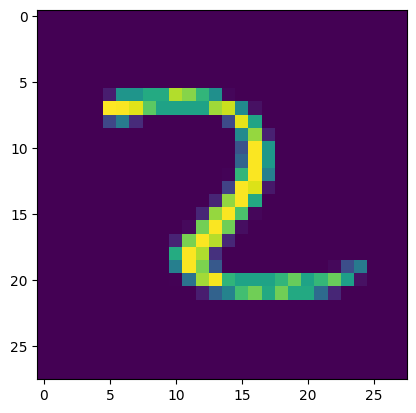

In [62]:
plt.imshow(X_test[2500])

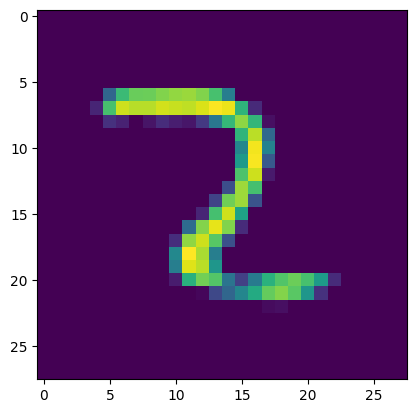

In [61]:
#plt.imshow(X_test[2500])
plt.imshow(y_pred[2500])

# 9 save model

In [64]:
model.save("denoising.h5")